In [1]:
# Q1
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt


In [2]:
# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50


In [3]:

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=False, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)


In [4]:

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Hidden Dense layers
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-2         # larger init (1e-5 is too small for a hidden layer)

# Initialize weights and biases
w1 = torch.randn(Din, H) * std   
b1 = torch.zeros(H)              
w2 = torch.randn(H, K) * std     
b2 = torch.zeros(K)              


In [ ]:

# Hyperparameters
iterations = 10    
lr = 1e-2          # larger learning rate for cross-entropy
lr_decay = 0.9     # Learning rate decay
reg = 0            # Regularization
loss_history = []


In [6]:

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                 # Batch size
        x_train = inputs.view(Ntr, -1)        # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)   # middle layer with sigmoid
        y_pred = h.mm(w2) + b2                   # output layer scores
        log_probs = torch.log_softmax(y_pred, dim=1)   # softmax (log form)

        # Loss calculation (Cross-Entropy with regularization)  
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * log_probs) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (torch.exp(log_probs) - y_train_onehot) / Ntr  # softmax + CE gradient
        dw2 = h.t().mm(dy_pred) + reg * w2                      
        db2 = dy_pred.sum(dim=0)                                 
        dh = dy_pred.mm(w2.t())                                  
        dz1 = dh * h * (1 - h)                                   
        dw1 = x_train.t().mm(dz1) + reg * w1                     
        db1 = dz1.sum(dim=0)                                     

        # Parameter update
        w1 -= lr * dw1   
        b1 -= lr * db1   
        w2 -= lr * dw2   
        b2 -= lr * db2   

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay


Epoch 1/10, Loss: 2.3001064372062685
Epoch 2/10, Loss: 2.292532916545868
Epoch 3/10, Loss: 2.2819195787906645
Epoch 4/10, Loss: 2.2673385045528414
Epoch 5/10, Loss: 2.249895380973816
Epoch 6/10, Loss: 2.231582973480225
Epoch 7/10, Loss: 2.214204929113388
Epoch 8/10, Loss: 2.1986715648174284
Epoch 9/10, Loss: 2.1851860897541044
Epoch 10/10, Loss: 2.173569760799408


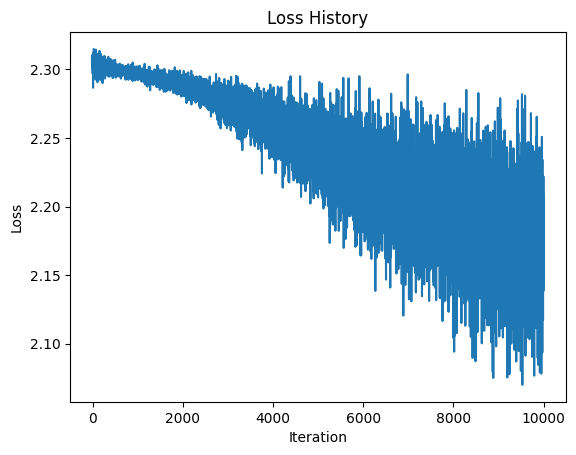

In [7]:

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


In [8]:

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)   
        y_train_pred = h.mm(w2) + b2              
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")


Training accuracy: 23.72%


In [9]:

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        h = torch.sigmoid(x_test.mm(w1) + b1)    
        y_test_pred = h.mm(w2) + b2               
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 24.09%
